# Disparidad condicional, replicación entre años y pruebas de situación


**Pregunta:** Una vez incluidos los controles permitidos, ¿queda una disparidad contra los solicitantes Black de Delaware que se repite año tras año, y encuentra la prueba de situación una disparidad que una comparación de iguales con iguales esconde?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 06 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este notebook puedes:

- ajustar el modelo de decisión de la aprobación sobre un indicador protegido y los controles permitidos, leer el efecto protegido con su razón de momios e intervalo de Wald, y ver cómo una variable sustituta omitida crea un efecto que desaparece cuando la variable sustituta es un control;
- ajustar el modelo lineal del diferencial de tasa, que descarta los créditos sin diferencial de tasa y nunca los imputa;
- comprobar si un efecto controlado hallado en un año se repite en el siguiente, por signo y por tamaño, en los seis pares de años de HMDA de Delaware;
- correr una prueba de situación paso a paso para un denunciante (k vecinos más cercanos por una distancia de Gower, un intervalo de Wald unilateral), correrla para todo denunciante bajo los comparadores ceteris paribus y mutatis mutandis sobre datos con un modelo estructural conocido, y leer la prueba de situación de HMDA versionada;
- decir qué es cada una de estas pruebas, en las palabras de los Procedimientos Interagenciales, y qué no es.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import conditional, plants, replication, situation
from riskvalidation.fairness.conditional import Effect
from riskvalidation.fairness.situation import SituationResult
from riskvalidation.validation import fairness as vf

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}
YN = {True: "sí", False: "no"}

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

- **La planta de variable sustituta del motor** (`riskvalidation.fairness.plants.ProxyFeaturePlant`): la decisión depende de tres covariables y de una variable sustituta correlacionada con el indicador protegido, y **nunca del propio indicador protegido**. La disparidad la transmite solo la variable sustituta, así que el efecto protegido dada la variable sustituta es exactamente cero (el `truth()` de la planta).
- **Dos conjuntos de datos pequeños escritos en este notebook**, con un modelo estructural enunciado en el texto para que la verdad se conozca: un modelo de solicitudes de crédito para la prueba de situación (el modelo estructural de la Sección 5.2 del artículo complementario, más abajo) y un modelo lineal del diferencial de tasa.
- **Los seis pares de años de HMDA de Delaware versionados** (`data/derived/C21/pair-2018-19.json` a `pair-2023-24.json`; propietario: este repositorio). HMDA son los datos de la Home Mortgage Disclosure Act del FFIEC y el CFPB (clase mirror-allowed; la frase de licencia de los datos está SIN VERIFICAR). Para cada par la cadena de cálculo ajustó el modelo de decisión controlado y el modelo del diferencial de tasa en el año $t$ y los reajustó en el año $t+1$. HMDA público retiene el puntaje de crédito, así que **los modelos llevan los controles que el usuario pudo aportar y el documento lista `credit_score` como faltante**; no se imputa nada. La primera celda abre los seis documentos e imprime el motor que los horneó.

In [2]:
# Abrir los seis pares de años versionados e imprimir la versión del motor, los años y las filas de cada uno
pairs = {}
for name in ("2018-19", "2019-20", "2020-21", "2021-22", "2022-23", "2023-24"):
    path = ROOT / "data" / "derived" / "C21" / f"pair-{name}.json"
    pairs[name] = json.loads(path.read_text(encoding="utf-8"))
    doc = pairs[name]
    o = doc["outputs"]
    print(f"{name}: año de ajuste {o['fit_year']} | año de confirmación {o['confirm_year']}", end=" ")
    print(f"| filas {o['scope']['rows_fit']} / {o['scope']['rows_confirm']}", end=" ")
    print(f"| horneado con riskvalidation {doc['provenance']['riskvalidation_version']}")

2018-19: año de ajuste 2018 | año de confirmación 2019 | filas 36515 / 41834 | horneado con riskvalidation 1.0.1
2019-20: año de ajuste 2019 | año de confirmación 2020 | filas 41834 / 63167 | horneado con riskvalidation 1.0.1
2020-21: año de ajuste 2020 | año de confirmación 2021 | filas 63167 / 71474 | horneado con riskvalidation 1.0.1
2021-22: año de ajuste 2021 | año de confirmación 2022 | filas 71474 / 42788 | horneado con riskvalidation 1.0.1
2022-23: año de ajuste 2022 | año de confirmación 2023 | filas 42788 / 30784 | horneado con riskvalidation 1.0.1
2023-24: año de ajuste 2023 | año de confirmación 2024 | filas 30784 / 33896 | horneado con riskvalidation 1.0.1


## Método

### Paso 1: la disparidad controlada, y la variable sustituta que la crea

Los Procedimientos Interagenciales describen la evidencia comparativa de trato dispar como diferencias de trato "no explicadas por completo por factores legítimos no discriminatorios". La forma estadística compara la decisión de solicitantes que se parecen en los controles permitidos. El motor ajusta un **modelo de decisión logístico** de la decisión favorable $d_i$ sobre un intercepto, el o los indicadores protegidos $a_i$ y los controles $c_i$:

$$\log\frac{P(d_i = 1)}{1 - P(d_i = 1)} = \beta_0 + \beta_A\, a_i + \boldsymbol\gamma^\top \mathbf{c}_i,$$

por el método de Newton con reducción de paso, sobre columnas estandarizadas y devolviendo los coeficientes en las unidades originales. El **efecto protegido** es $\hat\beta_A$ con su intervalo de Wald $\hat\beta_A \pm z_{1-(1-\ell)/2}\,\widehat{\mathrm{se}}$ y su razón de momios $e^{\hat\beta_A}$. El ajuste no lanza un error cuando no puede asentarse (separación completa o sin convergencia en 100 pasos): devuelve coeficientes NaN y `converged = False`.

El resultado es una **aproximación de evidencia comparativa**, nunca un hallazgo: los controles que el usuario no pudo aportar (aquí el puntaje de crédito) son una declaración del usuario. La planta lo ilustra: con solo las covariables como controles, el modelo de decisión halla un efecto protegido aunque la decisión nunca leyó el indicador protegido; con la variable sustituta entre los controles, el efecto es cero dentro del error. La celda siguiente ajusta ambos.

In [3]:
# Ajustar el modelo de decisión solo con las covariables y con la variable sustituta entre los controles
plant = plants.ProxyFeaturePlant(n=20000, proxy_strength=0.7, seed=3)
draw = plant.draw_default()
truth = plant.truth()
print(
    "efecto protegido verdadero dada la variable sustituta:",
    truth["protected_effect_given_proxy"],
    "| correlación de la variable sustituta con el indicador protegido:",
    truth["proxy_strength"],
)
protected_effects = {}
control_sets = (
    ("controles: solo covariables", draw["controls"]),
    ("controles: covariables y variable sustituta", draw["controls_with_proxy"]),
)
for label, controls in control_sets:
    model = conditional.fit_decision_model(draw["decision"], draw["protected"], controls)
    effect = conditional.protected_effect(model, 1)
    protected_effects[label] = effect
    print(
        f"{label:40s} convergió {YN[bool(model.converged)]} | n {model.n} | β {effect.coefficient:+.4f}",
        end=" ",
    )
    print(f"| razón de momios {effect.odds_ratio:.4f} | 95% [{effect.lo:+.4f}, {effect.hi:+.4f}]")

efecto protegido verdadero dada la variable sustituta: 0.0 | correlación de la variable sustituta con el indicador protegido: 0.7
controles: solo covariables              convergió sí | n 20000 | β +1.2710 | razón de momios 3.5643 | 95% [+1.2053, +1.3366]
controles: covariables y variable sustituta convergió sí | n 20000 | β -0.0341 | razón de momios 0.9665 | 95% [-0.1253, +0.0570]


Los dos coeficientes son la evidencia del paso y se leen mejor contra el valor verdadero. La celda siguiente dibuja cada
efecto protegido con su intervalo al 95% y una línea punteada en el efecto verdadero, que es cero.

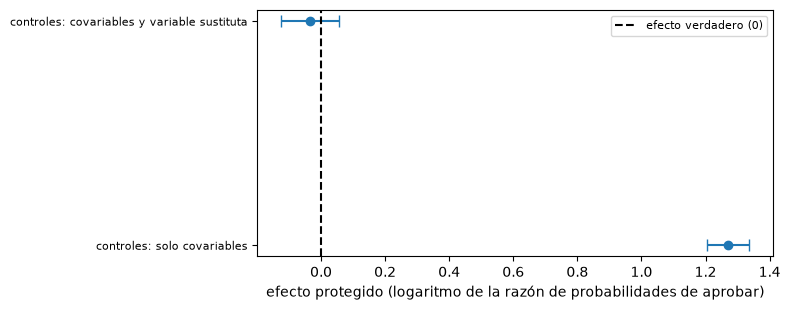

In [4]:
# Efecto protegido con su intervalo al 95%, con y sin la variable sustituta entre los controles
names = list(protected_effects)
coef = [protected_effects[n].coefficient for n in names]
lower = [protected_effects[n].coefficient - protected_effects[n].lo for n in names]
upper = [protected_effects[n].hi - protected_effects[n].coefficient for n in names]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(coef, range(len(names)), xerr=[lower, upper], fmt="o", capsize=4)
ax.axvline(0.0, color="black", linestyle="--", label="efecto verdadero (0)")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=8)
ax.set_xlabel("efecto protegido (logaritmo de la razón de probabilidades de aprobar)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Con solo las covariables el intervalo, de +1,2053 a +1,3366, está lejos de la línea punteada aunque la decisión nunca lee
el indicador protegido: la variable sustituta lleva la disparidad y el modelo se la asigna al grupo. Con la variable
sustituta entre los controles la estimación es -0,0341, con un intervalo de -0,1253 a +0,0570 que contiene el cero. Lo que
mide un efecto controlado depende de los controles que el analista pudo aportar, y en los datos públicos de HMDA el
puntaje de crédito es el que se retiene.

### Paso 2: el diferencial de tasa, un modelo lineal que descarta lo que no ve

Entre los créditos aprobados, el **diferencial de tasa** (la TAE del crédito menos un referente, en puntos porcentuales) es un segundo lugar donde puede haber una disparidad. El modelo lineal es el mismo diseño con un ajuste de mínimos cuadrados ordinarios, con errores estándar de la varianza residual $\mathrm{RSS}/(n-k)$:

$$s_i = \beta_0 + \beta_A\, a_i + \boldsymbol\gamma^\top \mathbf{c}_i + \varepsilon_i .$$

Los créditos sin diferencial de tasa (negados, o fuera de la regla de reporte) tienen un valor faltante, que el motor **descarta y nunca imputa**; el número descartado es las filas dadas menos el `n` del resultado. La celda siguiente escribe un conjunto de 6.000 créditos con un efecto conocido de 0,40 puntos porcentuales y el 20% de los diferenciales faltantes, y lo recupera.

In [5]:
# Un conjunto de 6.000 créditos con efecto protegido conocido de 0,40 puntos y 20% de diferenciales faltantes
rng = np.random.default_rng(5)
n_loans = 6000
a = (rng.random(n_loans) < 0.4).astype(float)
c = rng.standard_normal((n_loans, 2))
spread = 3.0 + 0.40 * a + 0.30 * c[:, 0] - 0.20 * c[:, 1] + 0.5 * rng.standard_normal(n_loans)
spread[rng.random(n_loans) < 0.2] = np.nan
model = conditional.fit_rate_spread_model(spread, a[:, None], c)
effect = conditional.protected_effect(model, 1)
print(
    "filas dadas:",
    n_loans,
    "| filas usadas:",
    model.n,
    "| filas descartadas, nunca imputadas:",
    n_loans - model.n,
)
print(f"β {effect.coefficient:+.4f} (verdadero +0.4000) | 95% [{effect.lo:+.4f}, {effect.hi:+.4f}]")
print("unidades: puntos porcentuales de diferencial de tasa")

filas dadas: 6000 | filas usadas: 4788 | filas descartadas, nunca imputadas: 1212
β +0.4195 (verdadero +0.4000) | 95% [+0.3909, +0.4482]
unidades: puntos porcentuales de diferencial de tasa


### Paso 3: replicación entre años

El dossier 08 pregunta si un hallazgo es estable de un año al otro. El motor compara el efecto ajustado en el año $t$ con el mismo efecto reajustado en el año $t+1$ por **signo y tamaño**, y no da otro veredicto:

$$\text{mismo signo} \iff \operatorname{sign}(\hat\beta^{(t)}) = \operatorname{sign}(\hat\beta^{(t+1)}), \qquad \text{razón de tamaño} = \hat\beta^{(t+1)} / \hat\beta^{(t)}$$

(negativa en un cambio de signo, indefinida cuando el coeficiente de ajuste es exactamente 0). La luz es ámbar cuando el signo difiere. Los documentos versionados guardan, para cada uno de los seis pares, el efecto controlado de cada grupo contra la referencia y su confirmación. La celda siguiente lee el grupo Black contra el White, reconstruye el `Effect` del motor para los dos años desde los coeficientes e intervalos versionados, llama a `replicate_effect` y a la prueba del motor, y compara con la razón versionada.

In [6]:
# Para los seis pares: el efecto controlado del grupo Black contra el White en el año t y t+1
fit_effects, confirm_effects = [], []
print(f"{'par':8s} {'β t':>8s} {'OR t':>7s} {'β t+1':>8s} {'razón de tamaño':>14s}", end=" ")
print(f"{'razón versionada':>16s} {'mismo signo':>10s} luz")
for name, doc in pairs.items():
    contrasts = doc["outputs"]["attributes"][0]["contrasts"]
    contrast = next(c for c in contrasts if c["group"].startswith("Black"))
    est = contrast["controlled"]["estimate"]
    ci = est["ci"]
    fit = Effect(est["coefficient"], float(np.exp(est["coefficient"])), ci["lo"], ci["hi"], ci["level"])
    conf_b = contrast["confirmation"]["estimate"]["confirm_coefficient"]
    confirm = Effect(conf_b, float(np.exp(conf_b)), conf_b, conf_b, 0.95)
    result = replication.replicate_effect(fit, confirm)
    row = vf.replication("hmda-logistic-decision", result)
    fit_effects.append(fit)
    confirm_effects.append(confirm)
    print(f"{name:8s} {fit.coefficient:+8.4f} {fit.odds_ratio:7.4f} {confirm.coefficient:+8.4f}", end=" ")
    print(f"{result.size_ratio:14.4f} {contrast['confirmation']['estimate']['size_ratio']:16.4f}", end=" ")
    print(f"{YN[bool(result.same_sign)]:>10s} {LIGHT[row.light.value]}")
print("controles:", est["controls"])
print("controles que el documento lista como faltantes:", est["missing_controls"])

par           β t    OR t    β t+1 razón de tamaño razón versionada mismo signo luz
2018-19   -0.7049  0.4941  -0.6904         0.9794           0.9794         sí verde
2019-20   -0.6904  0.5014  -0.5740         0.8314           0.8314         sí verde
2020-21   -0.5740  0.5632  -0.6397         1.1143           1.1143         sí verde
2021-22   -0.6397  0.5275  -0.5884         0.9199           0.9199         sí verde
2022-23   -0.5884  0.5552  -0.6196         1.0530           1.0530         sí verde
2023-24   -0.6196  0.5382  -0.5911         0.9540           0.9540         sí verde
controles: ['debt_to_income_ratio', 'combined_loan_to_value_ratio', 'income', 'loan_amount', 'property_value', 'loan_type', 'loan_purpose', 'lien_status', 'occupancy_type']
controles que el documento lista como faltantes: ['credit_score']


Seis filas de números esconden la imagen que importa para la replicación: si la estimación se mueve de un año a otro. La
celda siguiente dibuja el efecto controlado de cada año de ajuste con su intervalo al 95% y la estimación del año de
confirmación.

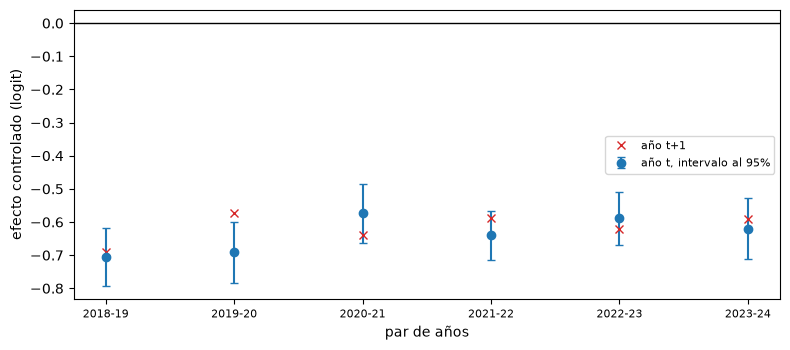

In [7]:
# Efecto controlado del grupo Black contra el White en cada par de años, con la estimación de confirmación
x = np.arange(len(pairs))
coef = [e.coefficient for e in fit_effects]
lower = [e.coefficient - e.lo for e in fit_effects]
upper = [e.hi - e.coefficient for e in fit_effects]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(x, coef, yerr=[lower, upper], fmt="o", capsize=3, label="año t, intervalo al 95%")
ax.plot(x, [e.coefficient for e in confirm_effects], "x", color="tab:red", label="año t+1")
ax.axhline(0.0, color="black", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(list(pairs), fontsize=8)
ax.set_xlabel("par de años")
ax.set_ylabel("efecto controlado (logit)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

El efecto es negativo en los seis pares, entre -0,7049 y -0,5740, y cada cruz roja, la estimación reajustada en el año
siguiente, cae cerca del intervalo del año anterior. Las razones de tamaño van de 0,8314 a 1,1143 y el signo nunca se
invierte, por lo que la luz de replicación del motor es verde en cada par. Es una afirmación sobre la estabilidad de la
estimación y no sobre su significado: el puntaje de crédito no está entre los nueve controles, y la replicación no puede
decir qué cambiaría al agregarlo.

### Paso 4: pruebas de situación, un denunciante a la vez

La prueba de situación pregunta, para un denunciante, si solicitantes parecidos del otro grupo fueron tratados mejor. El algoritmo siguiente está transcrito de Alvarez y Ruggieri (JAIR 82, 2025), Sección 4 y ecuaciones 3 a 10, y las funciones del motor siguen las ecuaciones del artículo.

1. **Distancia.** Solo sobre atributos no protegidos, la distancia de Gower promedia sobre los atributos la distancia de traslape (categóricos) y $|x_{1,i} - x_{2,i}| / (\max X_i - \min X_i)$ (continuos):
$$d(x_1, x_2) = \frac{1}{|X|}\sum_{i=1}^{|X|} d_i(x_{1,i}, x_{2,i}).$$
2. **Grupos.** El *grupo de control* son las $k$ filas más cercanas del grupo protegido al denunciante (excluido el denunciante); el *grupo de prueba* son las $k$ filas más cercanas del otro grupo (ceteris paribus) o a la **contrafactual** del denunciante (mutatis mutandis). Ni el atributo protegido ni la decisión entran en la distancia.
3. **Estadístico.** Con $p_c$ y $p_t$ las proporciones de decisiones **negativas** en el grupo de control y en el de prueba,
$$\Delta p = p_c - p_t .$$
4. **Evidencia.** Un caso potencial si $\Delta p > \tau$ (aquí $\tau = 0$); estadísticamente significativo al nivel $\alpha$ si la cota inferior del intervalo de Wald unilateral supera $\tau$:
$$\Delta p - z_{1-\alpha}\sqrt{\frac{p_c(1-p_c) + p_t(1-p_t)}{k}} \; > \; \tau .$$
5. **Varios atributos.** Para $q$ atributos protegidos cada uno se prueba al nivel $\alpha / q$ (Bonferroni).

Los datos son el modelo estructural del artículo de una solicitud de crédito, sacado aquí con nuestra propia semilla: $A \sim \mathrm{Bernoulli}(0{,}45)$ (el grupo protegido); $X_1 = -1500\,\mathrm{Poisson}(10)\,A + U_1$ con $U_1 = 10000\,\mathrm{Poisson}(10)$ (el sueldo anual); $X_2 = -300\,\chi^2_4\,A + 0{,}3\,X_1 + U_2$ con $U_2 = 2500\,N(0,1)$ (el saldo de la cuenta); y la decisión $\hat{Y} = \mathbb{1}[X_1 + 5 X_2 > 225000]$. **La decisión nunca lee $A$**: la disparidad llega solo a través de los mediadores $X_1$ y $X_2$. Como sacamos las ecuaciones estructurales, la contrafactual de un solicitante protegido bajo $do(A = 0)$ se conoce exacta: $X_1^{CF} = U_1$ y $X_2^{CF} = 0{,}3\,U_1 + U_2$. La celda siguiente saca 5.000 solicitantes y toma un denunciante: el primer solicitante protegido que es negado y que sería aprobado bajo su contrafactual.

In [8]:
# Sacar 5.000 solicitantes del modelo estructural de solicitudes de crédito; la decisión nunca lee el grupo
rng = np.random.default_rng(11)
n_app = 5000
protected = (rng.random(n_app) < 0.45).astype(int)
u1 = 10000 * rng.poisson(10, n_app)
u2 = 2500 * rng.standard_normal(n_app)
x1 = -1500 * rng.poisson(10, n_app) * protected + u1
x2 = -300 * rng.chisquare(4, n_app) * protected + 0.3 * x1 + u2
approved = (x1 + 5 * x2 > 225000).astype(int)
features = np.column_stack([x1, x2])
counterfactual = np.column_stack([u1, 0.3 * u1 + u2])
print("solicitantes:", n_app, "| proporción protegida:", round(float(protected.mean()), 4))
print("tasa de aprobación, protegidos:", round(float(approved[protected == 1].mean()), 4), end=" ")
print("| otros:", round(float(approved[protected == 0].mean()), 4))

solicitantes: 5000 | proporción protegida: 0.4536
tasa de aprobación, protegidos: 0.3792 | otros: 0.5999


Los datos están sacados; sigue el denunciante. La celda siguiente toma al primer solicitante protegido que es negado y
sería aprobado bajo el contrafactual, arma su grupo de control, su grupo de prueba y su grupo de prueba contrafactual con
las funciones del motor, y lee el estadístico y el intervalo unilateral para cada comparador.

In [9]:
# Tomar al primer solicitante protegido negado que sería aprobado bajo el contrafactual; armar sus grupos
K = 30
idx_p, idx_o = np.flatnonzero(protected == 1), np.flatnonzero(protected == 0)
cf_approved = counterfactual[:, 0] + 5 * counterfactual[:, 1] > 225000
complainant = np.flatnonzero((protected == 1) & (approved == 0) & cf_approved)[0]
is_categorical = np.zeros(2, dtype=bool)
scale_control, scale_test = np.ptp(features[idx_p], axis=0), np.ptp(features[idx_o], axis=0)
pool_control = idx_p[1:]
own = features[complainant]
near_control = pool_control[
    situation.k_nearest(own, features[pool_control], K, is_categorical, scale_control)
]
near_test = idx_o[situation.k_nearest(own, features[idx_o], K, is_categorical, scale_test)]
near_cf = idx_o[
    situation.k_nearest(counterfactual[complainant], features[idx_o], K, is_categorical, scale_test)
]
dist = situation.gower_distance(own, features[near_control[0]], is_categorical, scale_control)
print(
    "denunciante:",
    int(complainant),
    "| decisión:",
    approved[complainant],
    "| distancia a su vecino de control más cercano:",
    round(dist, 4),
)
for label, test_rows in (("ceteris paribus", near_test), ("mutatis mutandis", near_cf)):
    delta, p_c, p_t = situation.situation_statistic(approved[near_control], approved[test_rows])
    lower = situation.wald_interval_one_sided(delta, p_c, p_t, K, alpha=0.05)
    print(f"{label:20s} p_c {p_c:.4f} p_t {p_t:.4f} Δp {delta:+.4f}", end=" ")
    print(f"| cota inferior {lower:+.4f} | significativo {YN[lower > 0.0]}")
print("Nivel de Bonferroni para dos atributos protegidos:", situation.bonferroni_alpha(0.05, 2))

denunciante: 4 | decisión: 0 | distancia a su vecino de control más cercano: 0.0
ceteris paribus      p_c 1.0000 p_t 1.0000 Δp +0.0000 | cota inferior +0.0000 | significativo no
mutatis mutandis     p_c 1.0000 p_t 0.0000 Δp +1.0000 | cota inferior +1.0000 | significativo sí
Nivel de Bonferroni para dos atributos protegidos: 0.025


### Paso 5: la prueba para todo denunciante, dos comparadores

`situation_test` repite el paso 4 para todo denunciante del grupo protegido, sin importar su propia decisión, y devuelve el número de denunciantes, el de casos potenciales ($\Delta p > \tau$) y el de significativos. El comparador ceteris paribus construye el grupo de prueba alrededor del perfil propio del denunciante; el comparador mutatis mutandis lo construye alrededor de la contrafactual, aquí entregada por el modelo estructural. La proporción de denunciantes significativos es la cantidad que lee la luz del motor: verde hasta 0,20 (una convención fijada sobre un tamaño medido de 0,039 y una potencia de 1,000 con $n = 400$, $k = 30$), ámbar sobre ella, nunca roja. La celda siguiente corre ambos comparadores para $k = 15, 30$ y 50.

In [10]:
# Correr la prueba de situación para cada denunciante con ambos comparadores y tres tamaños de vecindad
counts = {}
print(f"{'k':>3s} {'comparador':20s} {'denunciantes':>13s} {'casos':>6s}", end=" ")
print(f"{'significativos':>14s} {'proporción':>10s} luz")
comparators = (
    ("ceteris paribus", {}),
    ("mutatis mutandis", {"comparator": "mutatis-mutandis", "counterfactual": counterfactual}),
)
for k in (15, 30, 50):
    for label, kwargs in comparators:
        result = situation.situation_test(features, protected, approved, k, **kwargs)
        counts[(k, label)] = result
        light = vf.situation_testing("loan-application model", result)
        share = result.n_significant / result.n_complainants
        print(
            f"{k:3d} {label:20s} {result.n_complainants:13d} {result.n_cases:6d} {result.n_significant:14d}",
            end=" ",
        )
        print(f"{share:10.4f} {LIGHT[light.light.value]}")

  k comparador            denunciantes  casos significativos proporción luz
 15 ceteris paribus               2268     51             28     0.0123 verde
 15 mutatis mutandis              2268    528            514     0.2266 ámbar
 30 ceteris paribus               2268     70             49     0.0216 verde
 30 mutatis mutandis              2268    559            544     0.2399 ámbar
 50 ceteris paribus               2268     85             66     0.0291 verde
 50 mutatis mutandis              2268    589            581     0.2562 ámbar


Los conteos en tres tamaños de vecindad y dos comparadores son doce números; el contraste entre los comparadores se ve
mejor como líneas. La celda siguiente dibuja los casos potenciales y los significativos contra k para ambos.

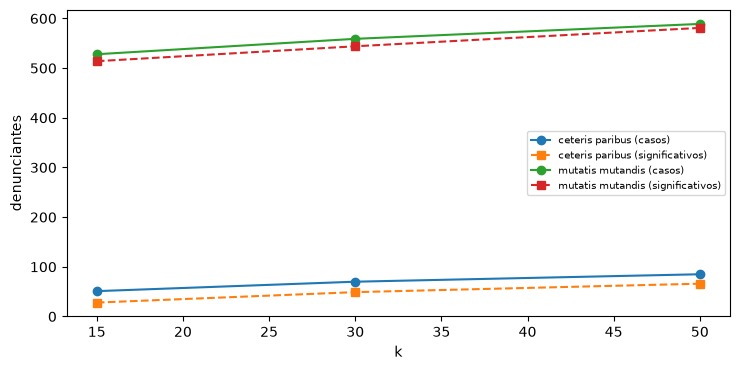

In [11]:
# Casos potenciales y significativos de los dos comparadores según el tamaño de la vecindad
ks = (15, 30, 50)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for label in ("ceteris paribus", "mutatis mutandis"):
    ax.plot(ks, [counts[(k, label)].n_cases for k in ks], "o-", label=label + " (casos)")
    ax.plot(ks, [counts[(k, label)].n_significant for k in ks], "s--", label=label + " (significativos)")
ax.set_xlabel("k")
ax.set_ylabel("denunciantes")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

El comparador ceteris paribus halla pocos denunciantes significativos en cualquier tamaño de vecindad (28, 49 y 66 para
k = 15, 30 y 50), mientras que el comparador mutatis mutandis halla muchos más (514, 544 y 581). Ambos crecen con k, pero
la brecha entre ellos es el hallazgo. La decisión nunca lee el atributo protegido, así que la disparidad está en los
mediadores, y solo un comparador construido alrededor del perfil contrafactual del denunciante puede verla. El
comparador es parte del resultado, no un detalle del método.

### Paso 6: la prueba de situación de HMDA versionada

La cadena de cálculo corrió la prueba ceteris paribus sobre los solicitantes de Delaware 2018, con el atributo raza como protegido, $k = 30$, $\alpha = 0{,}05$, $\tau = 0$ y la normalización por rango, sobre los atributos no protegidos de la solicitud. El comparador mutatis mutandis **no** se corrió: HMDA público no tiene un modelo causal estructural de la raza y los campos de suscripción, y el algoritmo necesita un generador contrafactual que aporta el usuario. La celda siguiente lee los conteos versionados, reconstruye el `SituationResult` del motor, llama a la prueba del motor y compara con la fila versionada, e imprime la razón por la que no se corrió la prueba contrafactual.

In [12]:
# Reconstruir el resultado de situación versionado, llamar a la prueba del motor y mostrarlo junto a la luz versionada
doc = pairs["2018-19"]
st = doc["outputs"]["situation_testing"]
result = SituationResult(
    st["n_complainants"], st["n_cases"], st["n_significant"], st["k"], float(st["tau"]), st["alpha"]
)
light = vf.situation_testing("hmda-situation-testing", result)
committed = next(t for t in doc["tests"] if t["test_id"] == "fair.situation_testing")
COMPARATORS = {"ceteris-paribus": "ceteris paribus"}
NORMS = {"range": "rango"}
print("atributo:", st["attribute"], "| comparador", COMPARATORS[st["comparator"]], "| k", st["k"], end=" ")
print("| normalización:", NORMS[st["distance_normalization"]])
share = result.n_significant / result.n_complainants
print(
    "denunciantes",
    result.n_complainants,
    "| casos",
    result.n_cases,
    "| significativos",
    result.n_significant,
    end=" ",
)
print("| proporción", round(share, 4))
print("luz del motor:", LIGHT[light.light.value], "| luz versionada:", LIGHT[committed["light"]])
print("comparador contrafactual corrido:", YN[st["counterfactual_test"]["run"]])
print("razón:", st["counterfactual_test"]["reason"]["es"])

atributo: derived_race | comparador ceteris paribus | k 30 | normalización: rango
denunciantes 4485 | casos 3286 | significativos 1179 | proporción 0.2629
luz del motor: ámbar | luz versionada: ámbar
comparador contrafactual corrido: no
razón: El HMDA público no entrega un conjunto contrafactual, de modo que la prueba contrafactual (mutatis mutandis) no se ejecuta.


## Resultados

**Respuesta:** Sí a lo primero, con una salvedad, y depende del comparador en lo segundo. El efecto controlado del grupo Black contra el White es negativo en los seis pares de años, de -0,7049 en 2018 a -0,5911 en 2024, con razones de tamaño entre 0,8314 y 1,1143, y el puntaje de crédito falta entre los controles. En los datos estructurales, donde la decisión nunca lee el atributo protegido, la prueba ceteris paribus da una proporción de denunciantes significativos de 0,0216 con k = 30 (verde) y la prueba mutatis mutandis 0,2399 (ámbar). La prueba de situación de HMDA versionada, solo ceteris paribus, tiene una proporción de 0,2629.

- **Una variable sustituta omitida crea un efecto, y un control la elimina.** En la planta de variable sustituta la decisión nunca lee el indicador protegido, y sin embargo el modelo de decisión con solo las covariables halla un efecto protegido de +1,2710 (razón de momios 3,5643, intervalo de 95% de +1,2053 a +1,3366). Con la variable sustituta entre los controles el efecto es -0,0341 (razón de momios 0,9665, intervalo de -0,1253 a +0,0570), que contiene el valor verdadero 0. El signo del primer efecto es el de la planta (la variable sustituta sube la aprobación); la lección es que un efecto controlado mide lo que los controles dejan fuera. En HMDA el control que los datos retienen es el puntaje de crédito.
- **El modelo del diferencial de tasa recupera un efecto conocido e informa qué descartó.** Con 6.000 créditos y el 20% de los diferenciales faltantes usa 4.788 filas y descarta 1.212, sin imputarlas nunca, y estima +0,4195 puntos porcentuales (intervalo de +0,3909 a +0,4482) para un valor verdadero de +0,4000.
- **La disparidad controlada de Delaware se repite todos los años.** Para el grupo Black contra el White el efecto controlado es negativo en los seis pares de años, de -0,7049 (razón de momios 0,4941) en 2018 a -0,5911 en 2024, con el mismo signo en cada año de confirmación y razones de tamaño entre 0,8314 y 1,1143. La luz de replicación del motor es verde en los seis. Los controles son los nueve que lista el documento (deuda sobre ingreso, préstamo sobre valor combinado, ingreso, monto del préstamo, valor de la propiedad, tipo de préstamo, propósito del préstamo, estado del gravamen, tipo de ocupación), y `credit_score` figura como faltante. La replicación es una afirmación sobre la estimación: no dice qué cambiaría el control faltante.
- **La prueba de situación ve lo que el comparador ceteris paribus no puede.** En los datos estructurales la decisión nunca lee el atributo protegido: los solicitantes protegidos se aprueban en 0,3792 contra 0,5999 por los mediadores. Para un denunciante (negado, y aprobado bajo su contrafactual) el comparador ceteris paribus halla el grupo de prueba también negado (Δp = 0), mientras que el comparador mutatis mutandis, cuyo grupo de prueba se construye alrededor de la contrafactual, halla Δp = +1,0000, significativo. Sobre los 2.268 solicitantes protegidos con k = 30, la prueba ceteris paribus halla 70 casos potenciales y 49 significativos (una proporción de 0,0216, verde), y la prueba mutatis mutandis 559 y 544 (una proporción de 0,2399, ámbar). Los conteos crecen con k en ambas. El comparador es el hallazgo: comparar iguales con iguales (en el perfil observado) esconde una disparidad que está en los mediadores.
- **La prueba de situación de HMDA versionada es solo ceteris paribus.** Probó a los 4.485 solicitantes protegidos por raza de 2018 con k = 30 y halló 3.286 casos potenciales y 1.179 significativos, una proporción de 0,2629 (ámbar, y el motor reconstruido desde los conteos da la misma luz). El comparador mutatis mutandis no se corrió, porque HMDA público no da datos contrafactuales. La proporción ceteris paribus no es comparable con la de los datos estructurales: aquí los solicitantes son reales y el puntaje de crédito no observado es parte de la diferencia.

Lo que los resultados no muestran: ninguna de estas pruebas identifica una causa ni una infracción. Los Procedimientos Interagenciales describen el análisis estadístico como una ayuda para una evaluación y no toman una disparidad bruta como prueba; la enmienda de 2026 de la Regulación B dice que la prueba de efectos no aplica bajo la ECOA, y la Fair Housing Act es una ley aparte. Los datos estructurales son sintéticos con nuestra semilla (el archivo propio del artículo no se redistribuye y sus conteos publicados no se reproducen aquí); el punto de corte ámbar 0,20 es una convención fijada sobre un tamaño y una potencia medidos.

## Resumen

- Una disparidad controlada es el efecto protegido de un modelo de decisión logístico (o de un modelo lineal del diferencial de tasa) dados los controles permitidos; es una aproximación de evidencia comparativa, una variable sustituta omitida crea un efecto, y un control faltante (el puntaje de crédito en HMDA público) es una declaración del usuario.
- El modelo del diferencial de tasa descarta las filas sin diferencial y nunca las imputa.
- La replicación compara el signo y el tamaño del efecto ajustado en el año $t$ con el reajuste en el año $t+1$; el efecto controlado del grupo Black contra el White de Delaware conserva su signo en los seis pares de años, y la luz del motor es verde en cada uno.
- La prueba de situación compara a cada denunciante con los $k$ solicitantes protegidos más cercanos y con los $k$ otros más cercanos (o los más cercanos a la contrafactual); sobre datos de estructura conocida el comparador mutatis mutandis halla la disparidad que está en los mediadores y el ceteris paribus no.
- La prueba de situación de HMDA versionada es solo ceteris paribus, porque HMDA público no tiene datos contrafactuales; ninguna de estas pruebas decide discriminación.

**Qué probar después.** El notebook 08 ubica estas pruebas entre las herramientas y bibliotecas que existen, y compara dos funciones del motor con referencias independientes.

## Referencias

- OCC, FDIC, Federal Reserve Board, OTS y NCUA (2009), Interagency Fair Lending Examination Procedures. https://www.federalreserve.gov/boarddocs/caletters/2009/0906/09-06_attachment.pdf
- CFPB (2026), Equal Credit Opportunity Act (Regulation B), regla final, 91 FR 21620, vigente desde 2026-07-21. https://www.govinfo.gov/content/pkg/FR-2026-04-22/pdf/2026-07804.pdf
- Alvarez, J. M. y Ruggieri, S. (2025), Counterfactual situation testing: from single to multidimensional discrimination, Journal of Artificial Intelligence Research 82, arXiv 2502.01267. https://doi.org/10.1613/jair.1.17935
- Alvarez, J. M. y Ruggieri, S. (2026), Mutatis mutandis: revisiting the comparator in discrimination testing, Computational Intelligence 42(4), arXiv 2405.13693. https://doi.org/10.1111/coin.70238
- FFIEC y CFPB, publicación de datos de la Home Mortgage Disclosure Act (la frase de licencia de los datos está SIN VERIFICAR). https://ffiec.cfpb.gov/data-publication/
- Kozodoi, N., Jacob, J. y Lessmann, S. (2022), Fairness in credit scoring: assessment, implementation and profit implications, European Journal of Operational Research 297(3). https://doi.org/10.1016/j.ejor.2021.06.023